In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
housing = fetch_california_housing()

df = pd.DataFrame(housing.data, columns=housing.feature_names)

#create target variable as a Pandas Series
target = pd.Series(housing.target, name="MedHouseVal")

# Add target to the DataFrame
df = pd.concat([df, target], axis=1)

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [15]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 20640
Number of columns: 9


In [16]:
print("Column names:")
print(df.columns.tolist())

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [17]:
print("MedInc       - Median income")
print("HouseAge     - Median house age")
print("AveRooms     - Average number of rooms")
print("AveBedrms    - Average number of bedrooms")
print("Population   - Population of the area")
print("AveOccup     - Average occupancy")
print("Latitude     - Latitude")
print("Longitude    - Longitude")
print("MedHouseVal  - Median house value (Target)")

MedInc       - Median income
HouseAge     - Median house age
AveRooms     - Average number of rooms
AveBedrms    - Average number of bedrooms
Population   - Population of the area
AveOccup     - Average occupancy
Latitude     - Latitude
Longitude    - Longitude
MedHouseVal  - Median house value (Target)


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [20]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [21]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [22]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0


In [23]:
print("Number of duplicate records:",
      df.duplicated().sum())

Number of duplicate records: 0


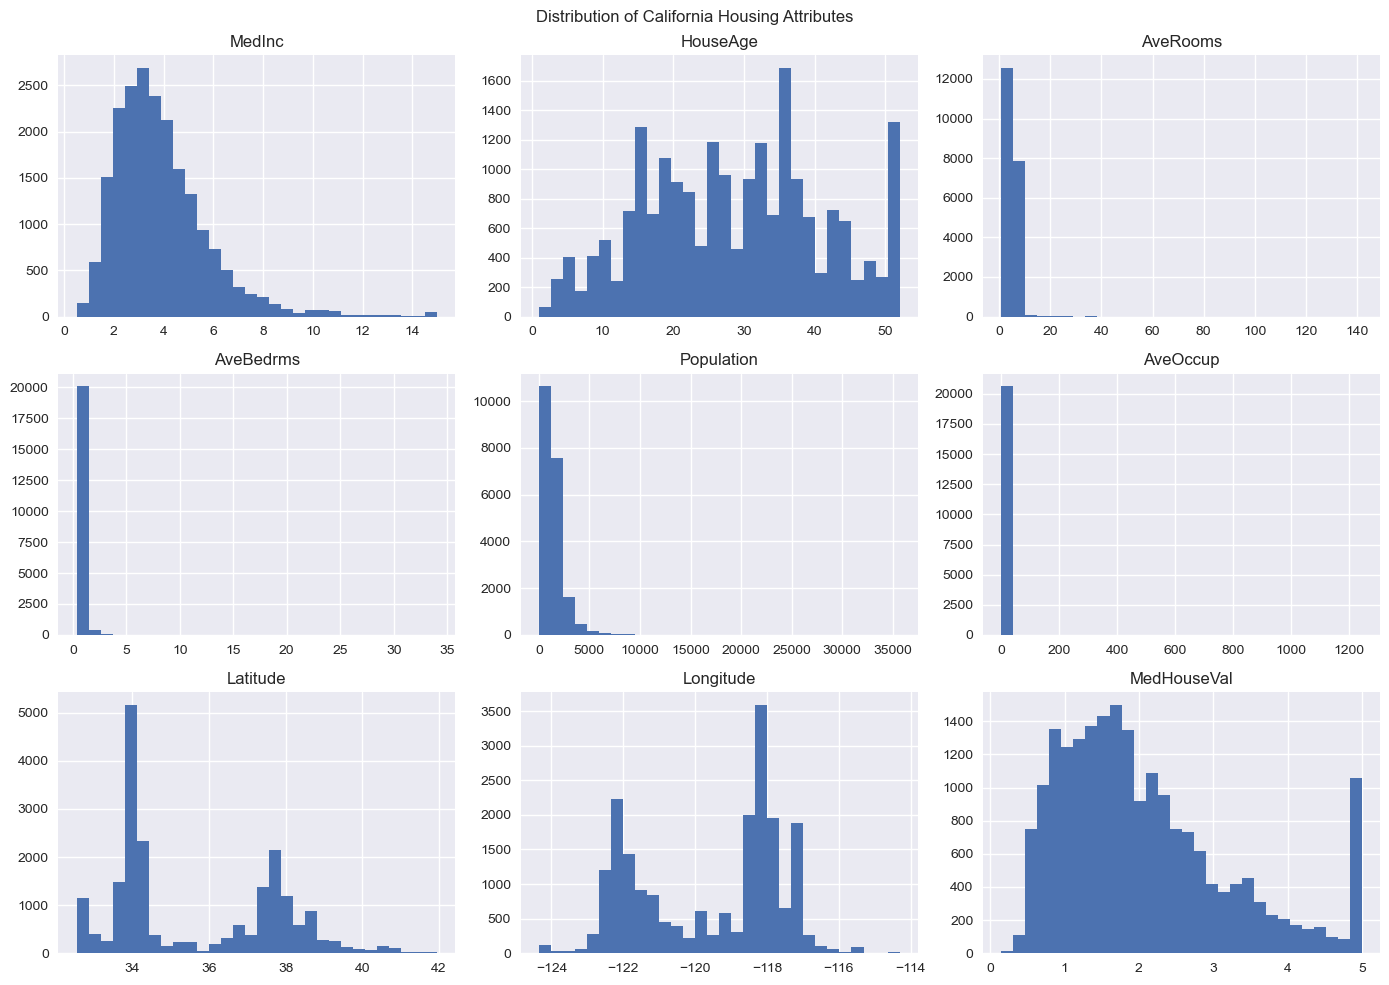

In [24]:
df.hist(figsize=(14, 10), bins=30)

plt.suptitle("Distribution of California Housing Attributes")
plt.tight_layout()
plt.show()

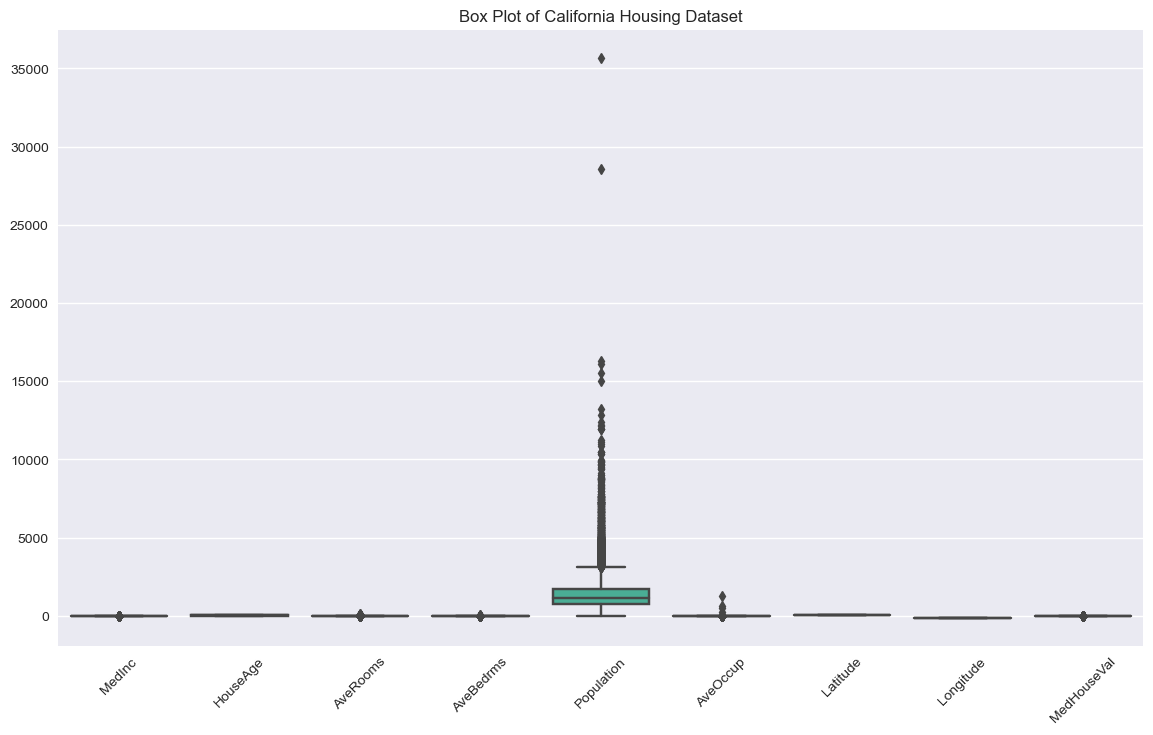

In [25]:
plt.figure(figsize=(14, 8))

sns.boxplot(data=df)

plt.title("Box Plot of California Housing Dataset")
plt.xticks(rotation=45)

plt.show()

In [26]:
#Q1 and Q3
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

#IQR
IQR = Q3 - Q1

#outliers
outliers = (
    (df < (Q1 - 1.5 * IQR)) |
    (df > (Q3 + 1.5 * IQR))
)

print("Number of outliers in each column:")
print(outliers.sum())

Number of outliers in each column:
MedInc          681
HouseAge          0
AveRooms        511
AveBedrms      1424
Population     1196
AveOccup        711
Latitude          0
Longitude         0
MedHouseVal    1071
dtype: int64


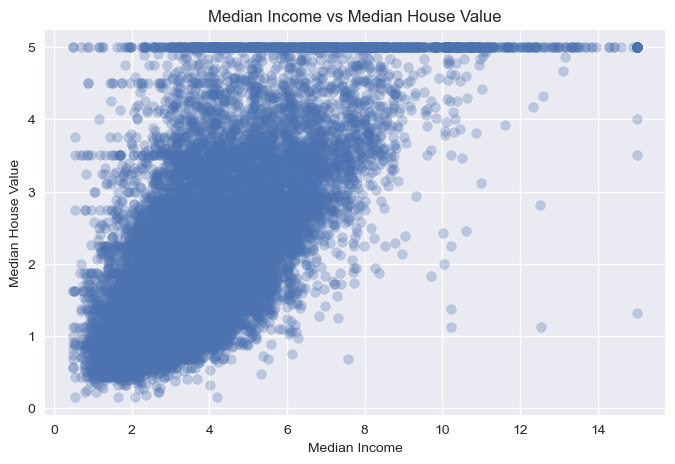

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.3
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")

plt.show()

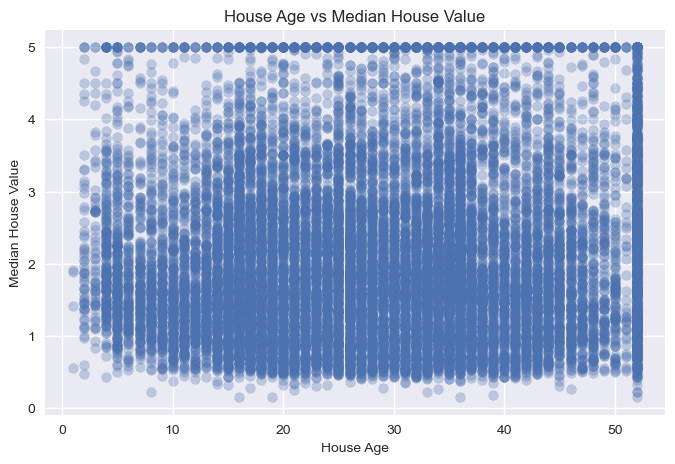

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["HouseAge"],
    df["MedHouseVal"],
    alpha=0.3
)

plt.xlabel("House Age")
plt.ylabel("Median House Value")
plt.title("House Age vs Median House Value")

plt.show()

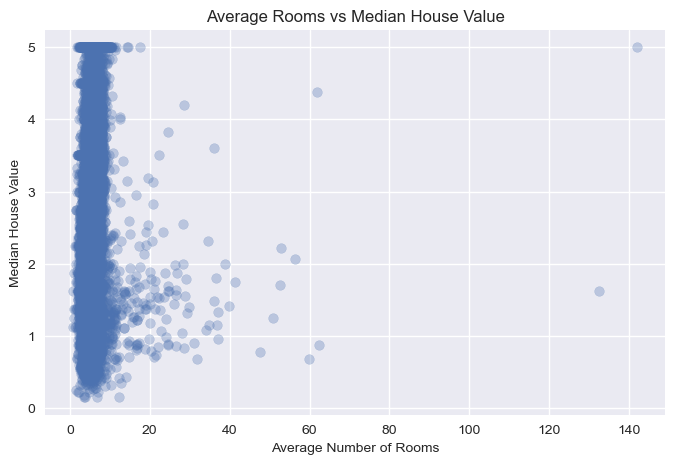

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["AveRooms"],
    df["MedHouseVal"],
    alpha=0.3
)

plt.xlabel("Average Number of Rooms")
plt.ylabel("Median House Value")
plt.title("Average Rooms vs Median House Value")

plt.show()

In [30]:
correlation = df.corr()

correlation

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


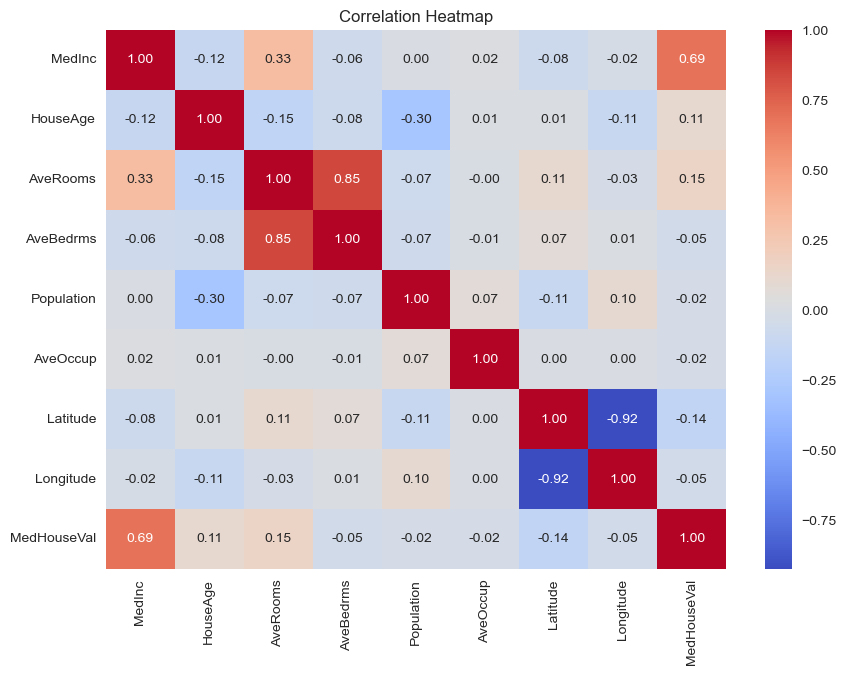

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [32]:
#filling missing values with median
for column in df.columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

print("Total missing values after treatment:",
      df.isnull().sum().sum())

Total missing values after treatment: 0


In [33]:
#columns where outliers will be treated
outlier_columns = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "MedHouseVal"
]

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower_limit,
        upper_limit
    )

print("Outliers have been treated.")

Outliers have been treated.


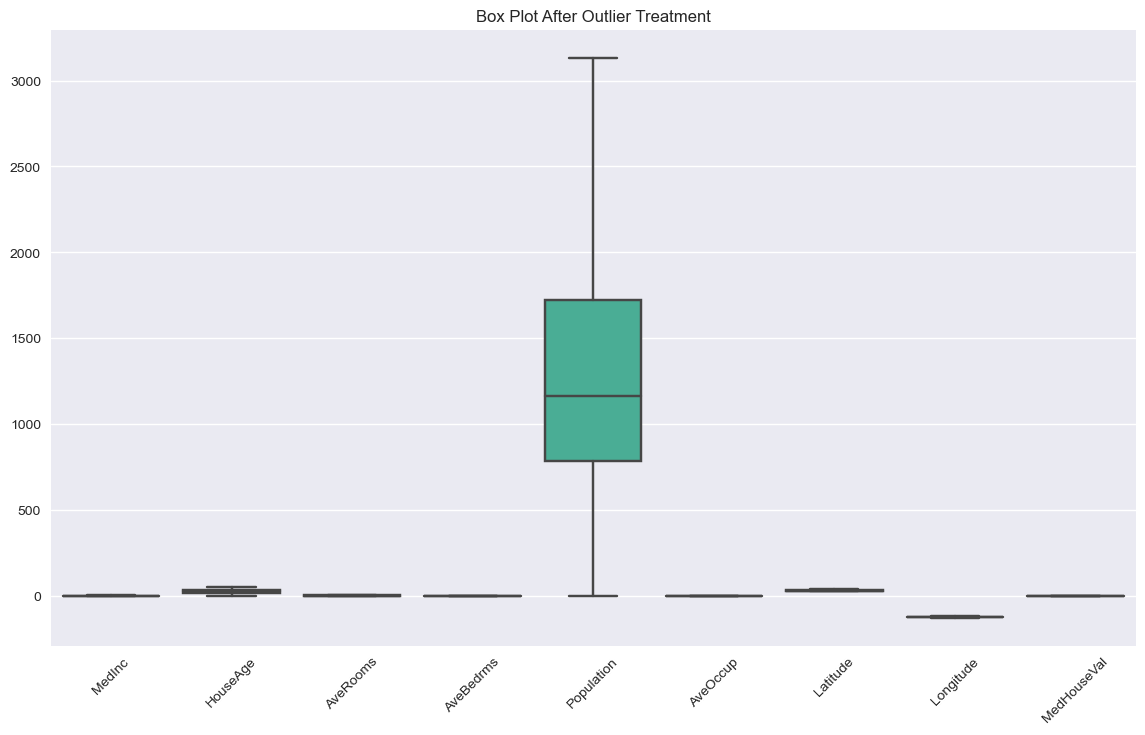

In [34]:
plt.figure(figsize=(14, 8))

sns.boxplot(data=df)

plt.title("Box Plot After Outlier Treatment")
plt.xticks(rotation=45)

plt.show()

In [35]:
#input features
X = df.drop("MedHouseVal", axis=1)

#target variable
y = df["MedHouseVal"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target:
MedHouseVal


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [37]:
#standard scaler
scaler = StandardScaler()

#scale training data
X_train_scaled = scaler.fit_transform(X_train)

#scale testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [38]:
#convert scaled training data into a dataframe
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_train_scaled_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,-0.331680,0.348490,-0.237303,-0.646096,1.257577,1.148740,-1.372811,1.272587
1,0.000933,1.618118,-0.673833,-0.217066,-0.031390,-1.678697,-0.876696,0.709162
2,0.207756,-1.952710,0.266670,-0.910345,-0.552990,-0.253025,-0.460146,-0.447603
3,-1.124019,0.586545,-1.051489,-0.306414,0.104566,1.586596,-1.382172,1.232698
4,-0.154455,1.142008,0.766160,0.939162,-0.606588,-0.865504,0.532084,-0.108551


In [40]:
print("FINAL CHECK: ")

print("\nDataset shape:")
print(df.shape)

print("\nTraining features:")
print(X_train.shape)

print("\nTesting features:")
print(X_test.shape)

print("\nTraining target:")
print(y_train.shape)

print("\nTesting target:")
print(y_test.shape)

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

FINAL CHECK: 

Dataset shape:
(20640, 9)

Training features:
(16512, 8)

Testing features:
(4128, 8)

Training target:
(16512,)

Testing target:
(4128,)

Total missing values:
0

Duplicate records:
0
